# M5: Attacks and percolation

**Paper section covered:** 5.1 (Random Failure vs Targeted Attack), Table 4, Fig. 11

## Goal
1. **Reproduce** the paper's attack experiment: rank airports by degree, betweenness and closeness, remove the top 5, and track the size of the largest connected component (LCC); compare with random removal.
2. **Test the paper's conclusions beyond its 5-node window:** it looks only at the first 5 removals, but "robust to random failure, fragile to targeted attack" is a claim about the whole network.
3. **Extend the analysis:** run each attack all the way to the end of the network, add stronger and more varied strategies (PageRank, eigenvector, k-core, strength), add **adaptive** attacks that re-rank after every removal, and use more damage measures than the LCC.

## What the paper does and claims
- Table 4: the top-5 airports by degree, betweenness and closeness.
- Fig. 11: LCC size as these nodes are removed one by one (plus a random removal).
- Claims: *betweenness* removal is most destructive ("a sharp drop with just removing 5 nodes"); degree and closeness removal "had similar impact with gentle decline"; random removal "had barely any effect"; hence "the network while resistant to random attack can collapse with targeted attack"; betweenness nodes act as "critical bridges between various regions".

## Plan
| Part | Content |
|---|---|
| A | Reproduce Table 4 and Fig. 11; explain what each removal cuts off |
| B | Run every attack to the end; compare strategies; how far does the paper's conclusion hold? |
| C | Adaptive attacks versus the paper's static ranking |
| D | More damage measures: connected pairs, efficiency, components |
| E | Random failure: simulation versus theory |
| F | Verdict |

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn
import attacks as at

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 25)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY, PURPLE, TEAL, BROWN = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777", "#8e5ea2", "#17a2b8", "#8c564b"
COL = {"degree": BLUE, "betweenness": RED, "closeness": GREEN, "pagerank": PURPLE, "eigenvector": TEAL, "kcore": BROWN, "strength": ORANGE, "random": "black"}

airports, routes = usfn.load_openflights()
G = usfn.build_country_network(airports, routes)
nodes = list(G.nodes)
N = len(nodes)
assert (N, G.number_of_edges()) == (541, 2780)
rng = np.random.default_rng(2025)
print(f"USFN: {N} nodes, {G.number_of_edges()} edges")

USFN: 541 nodes, 2780 edges


## Part A. Reproducing the paper

### A1. Setting and conventions
- **Network:** the unweighted 541-node USFN. All centralities are computed ignoring edge weights, as in the paper (confirmed in M1).
- **Static attack:** compute a centrality **once** on the intact network and remove airports in that order. This is what the paper does.
- **LCC:** the largest set of mutually reachable airports. Note that the removed nodes themselves leave the network, so even a "harmless" removal lowers the LCC by one.
- **Ties:** ORD and DEN both have degree 149. We break ties by position in the node list (stable sort); the paper's Table 4 uses the same order, ORD before DEN.
- **Random removal:** the paper shows one random run. We average **500 runs** and show a 5-95% band.

### A2. Table 4: the top 5 nodes

In [2]:
paper_t4 = {"degree": ["ATL", "ORD", "DEN", "DFW", "MSP"], "betweenness": ["ANC", "DEN", "ORD", "SEA", "ATL"], "closeness": ["DEN", "ORD", "LAS", "MSP", "SEA"]}
orders = {("static", name): at.static_order(G, name) for name in ["degree", "betweenness", "closeness", "pagerank", "eigenvector", "kcore", "strength"]}

t4 = pd.DataFrame({f"{m} (paper)": paper_t4[m] for m in paper_t4}).join(pd.DataFrame({f"{m} (ours)": orders[("static", m)][:5] for m in paper_t4}))
t4 = t4[[c for m in paper_t4 for c in (f"{m} (paper)", f"{m} (ours)")]]
t4.index = range(1, 6); t4.index.name = "rank"
display(t4)
for m in paper_t4: assert orders[("static", m)][:5] == paper_t4[m], m
print("Table 4 reproduced exactly.")
deg = dict(G.degree())
print("degree values of the top 5:", {n: deg[n] for n in orders[("static", "degree")][:5]})

,degree (paper),degree (ours),betweenness (paper),betweenness (ours),closeness (paper),closeness (ours)
rank,,,,,,
1,ATL,ATL,ANC,ANC,DEN,DEN
2,ORD,ORD,DEN,DEN,ORD,ORD
3,DEN,DEN,ORD,ORD,LAS,LAS
4,DFW,DFW,SEA,SEA,MSP,MSP
5,MSP,MSP,ATL,ATL,SEA,SEA


Table 4 reproduced exactly.
degree values of the top 5: {'ATL': 153, 'ORD': 149, 'DEN': 149, 'DFW': 138, 'MSP': 117}


**Table 4 reproduces exactly**, in all three columns and in order. Two observations the paper does not make: ORD and DEN are tied at 149 connections, so their order in the degree column is a tie-break, not a finding; and the three rankings overlap strongly (DEN, ORD, MSP, SEA, ATL each appear in at least two of them).

### A3. Fig. 11: LCC after removing the top airports

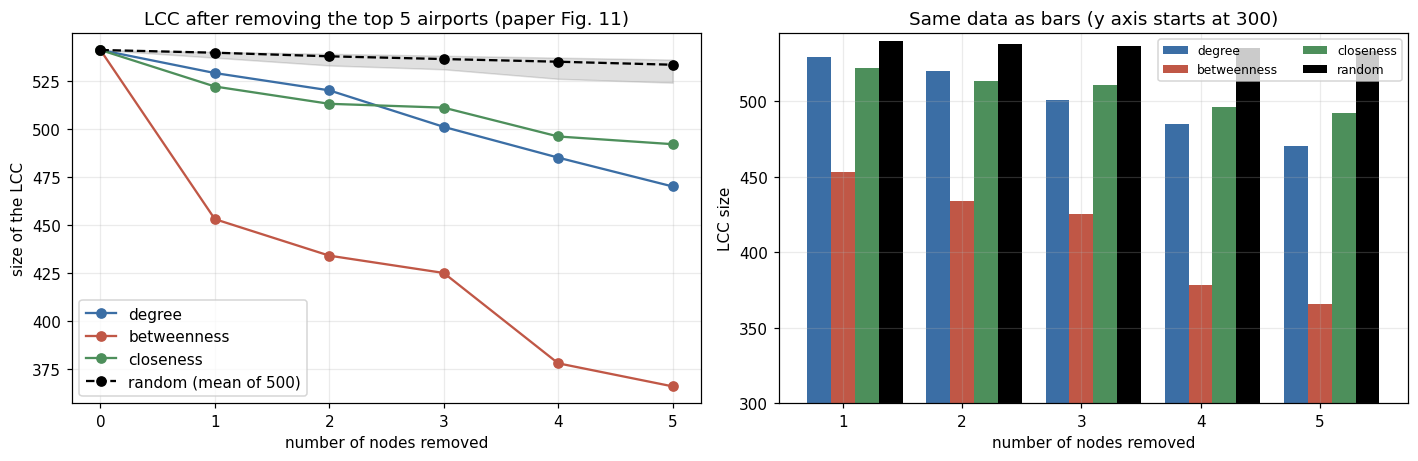

,degree,betweenness,closeness,random (mean)
removed,,,,
0,541,541,541,541.0
1,529,453,522,539.6
2,520,434,513,537.7
3,501,425,511,536.3
4,485,378,496,534.9
5,470,366,492,533.3


In [3]:
K = 5
curves = {m: at.percolation_curves(G, orders[("static", m)][:60])[0] for m in ["degree", "betweenness", "closeness"]}

N_RANDOM = 500
rand_lcc, rand_pair, rand_comp = [], [], []
for _ in range(N_RANDOM):
    o = list(rng.permutation(nodes))
    l, p, c = at.percolation_curves(G, o)
    rand_lcc.append(l); rand_pair.append(p); rand_comp.append(c)
rand_lcc, rand_pair, rand_comp = map(np.array, (rand_lcc, rand_pair, rand_comp))
rmean, rlo, rhi = rand_lcc.mean(0), np.percentile(rand_lcc, 5, axis=0), np.percentile(rand_lcc, 95, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for m in ["degree", "betweenness", "closeness"]:
    ax.plot(range(K + 1), curves[m][:K + 1], "o-", color=COL[m], label=f"{m}")
ax.plot(range(K + 1), rmean[:K + 1], "o--", color="black", label="random (mean of 500)")
ax.fill_between(range(K + 1), rlo[:K + 1], rhi[:K + 1], color="black", alpha=0.12)
ax.set_xlabel("number of nodes removed"); ax.set_ylabel("size of the LCC"); ax.set_title("LCC after removing the top 5 airports (paper Fig. 11)"); ax.legend()

ax = axes[1]
ks = np.arange(1, K + 1)
w = 0.2
for j, m in enumerate(["degree", "betweenness", "closeness"]):
    ax.bar(ks + (j - 1) * w, curves[m][ks], w, color=COL[m], label=m)
ax.bar(ks + 2 * w, rmean[ks], w, color="black", label="random")
ax.set_ylim(300, 545); ax.set_xlabel("number of nodes removed"); ax.set_ylabel("LCC size"); ax.set_title("Same data as bars (y axis starts at 300)"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

fig11 = pd.DataFrame({m: curves[m][:K + 1] for m in curves}); fig11["random (mean)"] = rmean[:K + 1].round(1)
fig11.index.name = "removed"; display(fig11)

**Fig. 11 reproduces, including the paper's description.** After 5 removals the LCC is **366** for betweenness, **470** for degree, **492** for closeness and about **533** for random removal (mean of 500 runs; the 5-95% band is about 524 to 536, so 5 random removals cost close to 5 airports). Betweenness is far the most destructive, degree and closeness give "gentler" declines, and random removal barely matters *on average*, as the paper says. One caveat the paper's single random run hides: random removal is occasionally unlucky. If it happens to pick a gateway such as ANC the damage is large (the worst of our 500 runs left an LCC of 450 after 5 removals), but that happens in only about 1% of runs.

### A4. What does each betweenness removal cut off?
The LCC drop at each step is the removed airport plus whatever it disconnects. Splitting the two shows why betweenness is so effective in the first steps.

In [4]:
H = G.copy()
prev = set(max(nx.connected_components(H), key=len))
rows = []
ak = {n for n in nodes if G.nodes[n]["lat"] > 50}
for step, n in enumerate(orders[("static", "betweenness")][:8], start=1):
    H.remove_node(n)
    lcc_now = set(max(nx.connected_components(H), key=len))
    cut = prev - lcc_now - {n}
    rows.append({"step": step, "removed": n, "LCC after": len(lcc_now), "LCC drop": len(prev) - len(lcc_now),
                 "airports cut off (besides the removed one)": len(cut), "of which in Alaska": len(cut & ak),
                 "examples": ", ".join(sorted(cut)[:5])})
    prev = lcc_now
pd.DataFrame(rows).style.hide(axis="index")

step,removed,LCC after,LCC drop,airports cut off (besides the removed one),of which in Alaska,examples
1,ANC,453,88,87,87,"ABL, ADK, ADQ, AKK, AKN"
2,DEN,434,19,18,0,"AIA, BFF, CDR, CEZ, CYS"
3,ORD,425,9,8,0,"ALO, CMX, DBQ, EAU, FOE"
4,SEA,378,47,46,43,"AET, AGN, AIN, AKP, ALW"
5,ATL,366,12,11,0,"ABY, BQK, CSG, DHN, GLH"
6,MSP,351,15,14,0,"ABR, ATY, BJI, BRD, DIK"
7,DFW,335,16,15,0,"ABI, ACT, BPT, CMI, COU"
8,BET,335,0,0,0,


**Reading this.**
- Almost all of the first-step damage is a single event: removing **ANC** cuts off 87 Alaskan airports (the Alaska result from M1). The fourth removal, **SEA**, cuts off another 43 Alaskan airports (the remaining Alaskan airports reach the mainland through SEA), so ANC and SEA together isolate 130 of Alaska's 131 airports.
- Other steps cut off 8 to 18 airports each, mostly small airports whose only link was the removed hub.
- Step 8 shows a weakness of a *static* ranking: BET (Bethel) is in the list, but it is already cut off from the main network, so removing it changes nothing (LCC stays at 335). A static list cannot know this; an adaptive attacker would skip it.
- So betweenness is effective because it finds *bridges*, whose removal strands whole groups, rather than merely large airports.

## Part B. Running the attack to the end: how far does the paper's conclusion hold?

The paper stops after 5 removals. Here we run every attack through the whole network. In addition to the paper's three rankings we add **PageRank**, **eigenvector centrality**, **k-core** (coreness, ties broken by degree) and **strength** (weighted degree; the only weighted ranking, see M7). We measure:
- **LCC size** (as in the paper),
- the **robustness index R** (Schneider et al. 2011): the average LCC fraction over all removals; 1 means perfectly robust and small values mean fragile,
- **k50 and k10**: how many airports must be removed before the LCC falls to 50% and 10% of the original size.

In [5]:
names = ["degree", "betweenness", "closeness", "pagerank", "eigenvector", "kcore", "strength"]
res = {}
for m in names:
    lcc, pair, comp = at.percolation_curves(G, orders[("static", m)])
    res[("static", m)] = {"lcc": lcc, "pair": pair, "comp": comp}

def summarize(label, lcc):
    return {"strategy": label, "R": at.robustness_R(lcc, N), "k50": at.k_to_reach(lcc, N, 0.5), "k10": at.k_to_reach(lcc, N, 0.1),
            "LCC after 5": lcc[5], "LCC after 20": lcc[20], "LCC after 50": lcc[50]}

rows = [summarize(f"static {m}", res[("static", m)]["lcc"]) for m in names]
rows.append(summarize("random (mean of 500)", rmean))
st = pd.DataFrame(rows)
st["k50 as % of N"] = (100 * st.k50 / N).round(1); st["k10 as % of N"] = (100 * st.k10 / N).round(1)
st.sort_values("R").style.hide(axis="index").format({"R": "{:.3f}", "LCC after 5": "{:.0f}", "LCC after 20": "{:.0f}", "LCC after 50": "{:.0f}", "k50 as % of N": "{:.1f}", "k10 as % of N": "{:.1f}"})

strategy,R,k50,k10,LCC after 5,LCC after 20,LCC after 50,k50 as % of N,k10 as % of N
static pagerank,0.049,15,58,470,226,92,2.8,10.7
static betweenness,0.061,19,80,366,265,158,3.5,14.8
static degree,0.062,35,52,470,353,60,6.5,9.6
static strength,0.073,41,69,477,378,108,7.6,12.8
static closeness,0.093,15,108,492,235,119,2.8,20.0
static kcore,0.102,44,100,470,353,263,8.1,18.5
static eigenvector,0.128,44,110,479,376,260,8.1,20.3
random (mean of 500),0.389,192,422,533,509,463,35.5,78.0


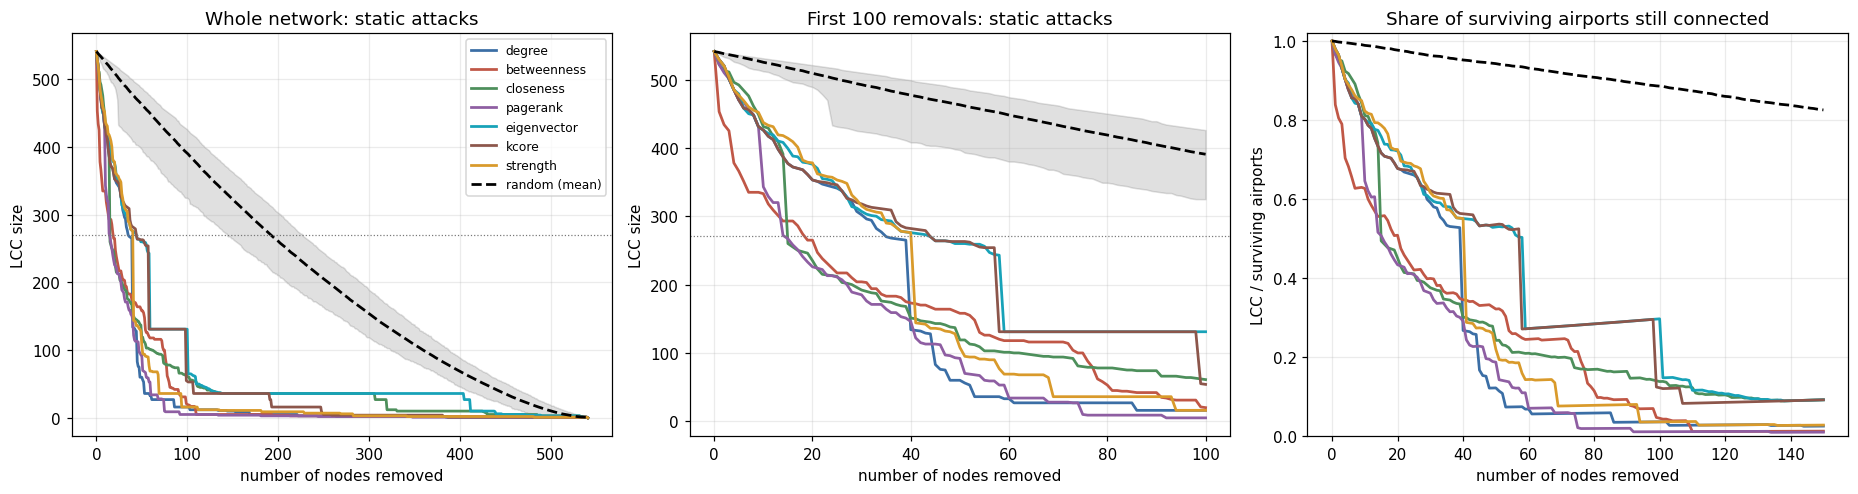

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ks = np.arange(N + 1)
for ax, xmax, title in [(axes[0], N, "Whole network"), (axes[1], 100, "First 100 removals")]:
    for m in names:
        ax.plot(ks[:xmax + 1], res[("static", m)]["lcc"][:xmax + 1], color=COL[m], lw=1.8, label=m)
    ax.plot(ks[:xmax + 1], rmean[:xmax + 1], color="black", lw=1.8, ls="--", label="random (mean)")
    ax.fill_between(ks[:xmax + 1], rlo[:xmax + 1], rhi[:xmax + 1], color="black", alpha=0.12)
    ax.axhline(N / 2, color=GREY, lw=0.8, ls=":")
    ax.set_xlabel("number of nodes removed"); ax.set_ylabel("LCC size"); ax.set_title(f"{title}: static attacks")
axes[0].legend(fontsize=8)
# share of the surviving airports that are still in the main network
ax = axes[2]
for m in names:
    ax.plot(ks[:151], res[("static", m)]["lcc"][:151] / (N - ks[:151]), color=COL[m], lw=1.8, label=m)
ax.plot(ks[:151], rmean[:151] / (N - ks[:151]), color="black", lw=1.8, ls="--", label="random (mean)")
ax.set_ylim(0, 1.02); ax.set_xlabel("number of nodes removed"); ax.set_ylabel("LCC / surviving airports")
ax.set_title("Share of surviving airports still connected")
plt.tight_layout(); plt.show()

**Reading this.**
- **Random failure is far less damaging than any targeted strategy:** halving the LCC takes about 190 random removals (35% of the network), but only 15 to 44 targeted ones (3% to 8%). For random failure the survivors stay mostly connected (right panel: still above 90% for the first 80 or so removals), whereas targeted attacks strand many survivors within a few removals. This supports the paper's main message.
- **"Betweenness is the most destructive" depends on the window.** It holds for the first few removals (the paper's window of 5), but by 50% damage (k50) betweenness (19 removals) is overtaken by closeness and PageRank (15 each). By the robustness index R, the most damaging *static* strategy is actually **PageRank (0.049)**, ahead of betweenness (0.061) and degree (0.062).
- **Degree and closeness are not "similar"** beyond the first 5. Closeness drops quickly in the middle range (LCC at 50% after 15 removals, against 35 for degree) but then leaves a stubborn core: it needs 108 removals to reach 10% (degree: 52), so its overall robustness index is higher (0.093 vs 0.062).
- **The long flat plateaus at 131** (k-core, eigenvector, and others) are the intact Alaskan network: those strategies target lower-48 hubs, so once the mainland has shattered, Alaska, untouched, is the largest component.

### B2. Which static strategy is the most damaging at each point?

Most damaging static strategy after k removals (smallest LCC):
   k =  1 to 13:  betweenness
   k = 14 to 14:  pagerank
   k = 15 to 17:  closeness
   k = 18 to 20:  pagerank
   k = 21 to 22:  closeness
   k = 23 to 23:  pagerank
   k = 24 to 24:  closeness
   k = 25 to 25:  pagerank
   k = 26 to 26:  closeness
   k = 27 to 39:  pagerank
   k = 40 to 40:  degree
   k = 41 to 44:  pagerank
   k = 45 to 60:  degree


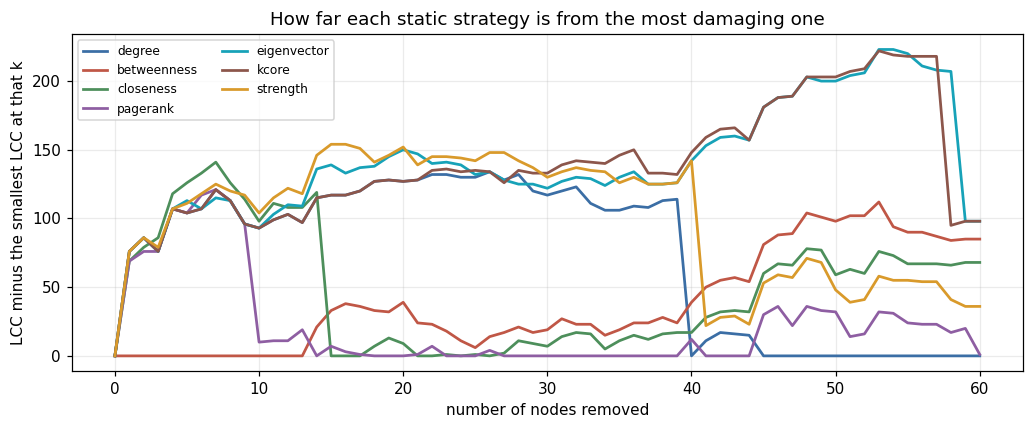

In [7]:
kmax = 60
lcc_mat = pd.DataFrame({m: res[("static", m)]["lcc"][:kmax + 1] for m in names})
winner = lcc_mat.iloc[1:].idxmin(axis=1)                               # strategy with the smallest LCC after k removals
runs, cur, start = [], winner.iloc[0], 1
for k in range(2, kmax + 1):
    if winner.loc[k] != cur:
        runs.append((cur, start, k - 1)); cur, start = winner.loc[k], k
runs.append((cur, start, kmax))
print("Most damaging static strategy after k removals (smallest LCC):")
for m, a, b in runs: print(f"   k = {a:2d} to {b:2d}:  {m}")

fig, ax = plt.subplots(figsize=(9.5, 4))
gap = lcc_mat.sub(lcc_mat.min(axis=1), axis=0)
for m in names: ax.plot(range(kmax + 1), gap[m], color=COL[m], lw=1.8, label=m)
ax.set_xlabel("number of nodes removed"); ax.set_ylabel("LCC minus the smallest LCC at that k"); ax.set_title("How far each static strategy is from the most damaging one")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

**Reading this.** No single centrality is the most damaging at every point. Betweenness leads for the first 13 removals (thanks to ANC and SEA), PageRank and closeness alternate from 14 to 44, and degree takes over from 45. The paper's conclusion "betweenness is the most destructive" is a statement about a very small window, not a general property.

### B3. Who are the targets?
The strategies target different airports. Here are the top 10 for each, and how much the top-20 sets overlap (Jaccard index).

,degree,betweenness,closeness,pagerank,eigenvector,kcore,strength
rank,,,,,,,
1,ATL,ANC,DEN,DEN,ATL,ATL,ATL
2,ORD,DEN,ORD,ATL,ORD,ORD,ORD
3,DEN,ORD,LAS,ORD,DEN,DEN,DFW
4,DFW,SEA,MSP,DFW,DFW,DFW,DEN
5,MSP,ATL,SEA,MSP,DTW,MSP,LAX
6,DTW,MSP,LAX,LAS,MSP,DTW,CLT
7,LAS,DFW,PHX,DTW,CLT,LAS,PHX
8,CLT,BET,SLC,CLT,LAS,CLT,PHL
9,IAH,FAI,ATL,IAH,IAH,IAH,LAS


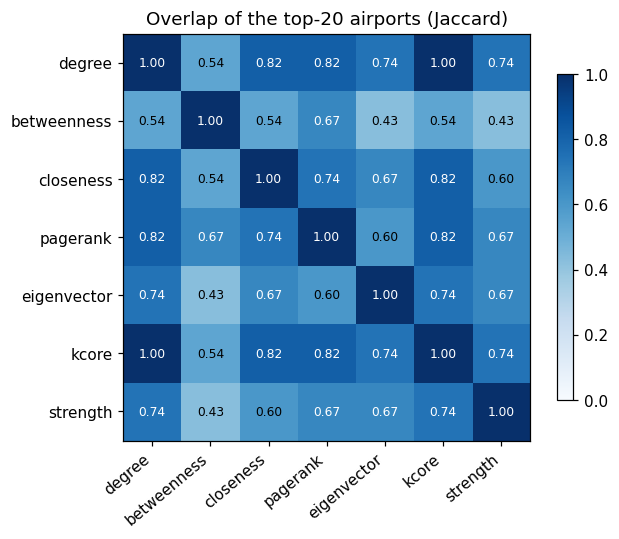

In [8]:
top10 = pd.DataFrame({m: orders[("static", m)][:10] for m in names}); top10.index = range(1, 11); top10.index.name = "rank"
display(top10)

top20 = {m: set(orders[("static", m)][:20]) for m in names}
J = pd.DataFrame([[len(top20[a] & top20[b]) / len(top20[a] | top20[b]) for b in names] for a in names], index=names, columns=names)
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(J.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=40, ha="right"); ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)): ax.text(j, i, f"{J.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if J.values[i, j] > 0.6 else "black")
ax.set_title("Overlap of the top-20 airports (Jaccard)"); ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

**Reading this.** Degree, k-core, strength and PageRank pick mostly the same big hubs (ATL, ORD, DEN, DFW, MSP), while **betweenness** picks several lower-degree *gateways* (ANC, SEA, and Alaskan hubs such as BET and FAI) and **closeness** picks geographically central airports (DEN, ORD, LAS). That is why the strategies damage the network in different ways: hub removal reduces connectivity broadly, gateway removal strands regions.

## Part C. Adaptive attacks
A static ranking is computed once, but removing a hub changes every other airport's centrality: removing DEN makes ORD more important, for example. A smart attacker would **re-rank after every removal**. This is the stronger, standard "worst-case" attack, and the paper does not run it. Adaptive attacks can only do at least as well as static ones in the first step and usually do better afterwards.

In [9]:
adaptive_names = ["degree", "betweenness", "closeness", "pagerank", "kcore", "strength"]
for m in adaptive_names:
    orders[("adaptive", m)] = at.adaptive_order(G, m)
    lcc, pair, comp = at.percolation_curves(G, orders[("adaptive", m)])
    res[("adaptive", m)] = {"lcc": lcc, "pair": pair, "comp": comp}

rows = []
for m in adaptive_names:
    s, a = res[("static", m)]["lcc"], res[("adaptive", m)]["lcc"]
    rows.append({"centrality": m, "R static": at.robustness_R(s, N), "R adaptive": at.robustness_R(a, N),
                 "k50 static": at.k_to_reach(s, N, .5), "k50 adaptive": at.k_to_reach(a, N, .5),
                 "k10 static": at.k_to_reach(s, N, .1), "k10 adaptive": at.k_to_reach(a, N, .1),
                 "first 5 removed (adaptive)": ", ".join(orders[("adaptive", m)][:5])})
ad = pd.DataFrame(rows); ad.style.hide(axis="index").format({"R static": "{:.3f}", "R adaptive": "{:.3f}"})

centrality,R static,R adaptive,k50 static,k50 adaptive,k10 static,k10 adaptive,first 5 removed (adaptive)
degree,0.062,0.051,35,33,52,49,"ATL, ORD, DEN, DFW, MSP"
betweenness,0.061,0.036,19,14,80,43,"ANC, SEA, DEN, ATL, DFW"
closeness,0.093,0.048,15,26,108,42,"DEN, ORD, MSP, LAS, SEA"
pagerank,0.049,0.042,15,14,58,53,"DEN, ATL, ORD, DFW, MSP"
kcore,0.102,0.055,44,36,100,50,"ATL, ORD, DEN, DFW, MSP"
strength,0.073,0.052,41,30,69,51,"ATL, ORD, DFW, DEN, LAX"


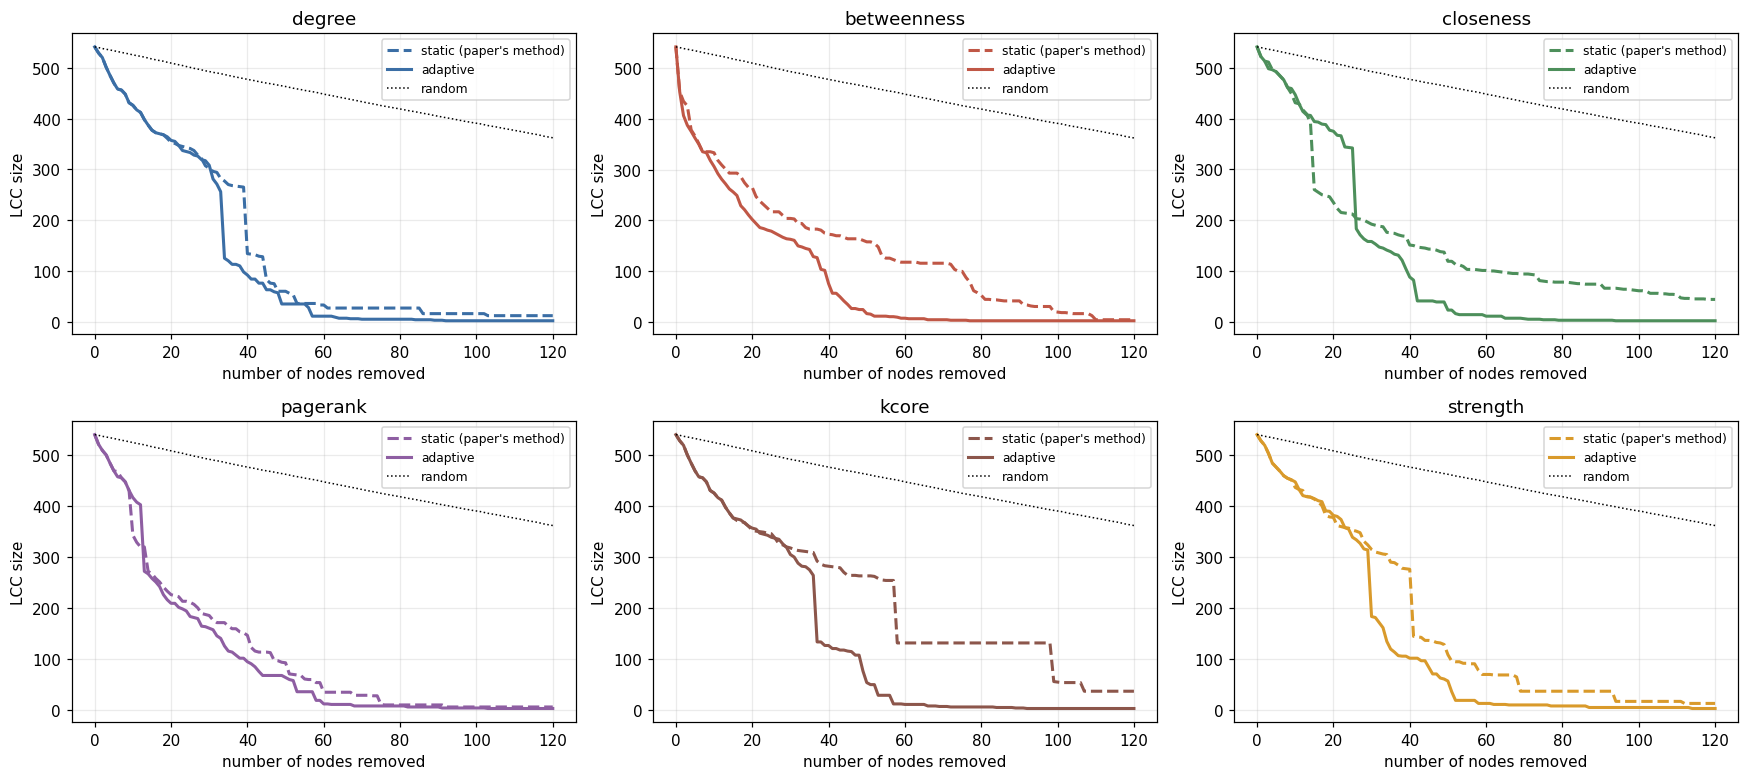

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7.2))
for ax, m in zip(axes.ravel(), adaptive_names):
    ax.plot(range(121), res[("static", m)]["lcc"][:121], color=COL[m], lw=2, ls="--", label="static (paper's method)")
    ax.plot(range(121), res[("adaptive", m)]["lcc"][:121], color=COL[m], lw=2, label="adaptive")
    ax.plot(range(121), rmean[:121], color="black", lw=1, ls=":", label="random")
    ax.set_title(f"{m}"); ax.set_xlabel("number of nodes removed"); ax.set_ylabel("LCC size"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading this.**
- Adaptive attacks have a lower robustness index than static ones for **every** centrality, so they are the stronger worst case. The gain differs: R roughly halves for **closeness** (0.093 to 0.048) and **k-core** (0.102 to 0.055), whose static rankings are redundant (they keep picking neighbouring hubs); it falls by 40% for **betweenness** (0.061 to 0.036); and it hardly changes for **PageRank** (0.049 to 0.042), whose static ranking already accounts for such effects.
- **Adaptive betweenness is the most damaging attack overall** (lowest R of all strategies, 0.036; 10% LCC after about 43 removals versus 80 static). Its first five targets are ANC, SEA, DEN, ATL, DFW, against ANC, DEN, ORD, SEA, ATL for the static list: after ANC is gone the attacker sees that SEA is now the critical gateway and that ORD is redundant, exactly the information a static list lacks (cf. the wasted removal of BET in A4).
- One subtlety: adaptive closeness reaches 50% damage *later* than static closeness (26 vs 15 removals) but finishes much faster (10% after 42 vs 108), so "adaptive is stronger" is a statement about the whole curve, not every point.
- The paper's static results therefore **understate** the real vulnerability, especially for betweenness-based attacks.

## Part D. More damage measures
The LCC is one number. We also track three others as nodes are removed:
- **connected-pair fraction:** the fraction of all airport pairs that can still reach each other (accounts for fragmentation and removed airports),
- **global efficiency:** the sum of 1/distance over all pairs of surviving airports, relative to the intact network (accounts for longer detours, not just disconnection),
- **number of components:** how fragmented the network is.

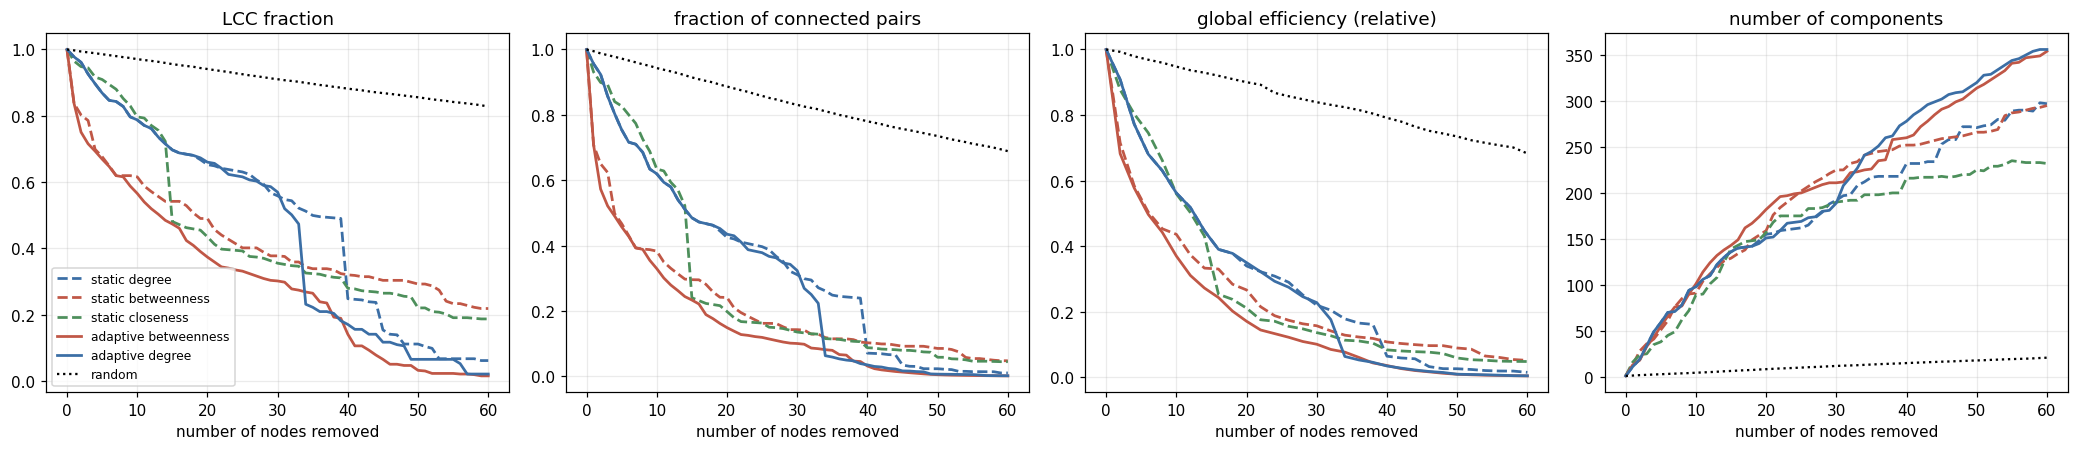

after removing 20 airports (3.7% of the network):


,static degree,static betweenness,static closeness,adaptive betweenness,adaptive degree,random (mean)
LCC fraction,0.652,0.490,0.434,0.373,0.660,0.941
connected pairs,0.425,0.242,0.199,0.149,0.435,0.887
efficiency,0.339,0.266,0.211,0.171,0.350,0.900
components,155.000,159.000,157.000,182.000,151.000,8.288


In [11]:
sel = [("static", "degree"), ("static", "betweenness"), ("static", "closeness"), ("adaptive", "betweenness"), ("adaptive", "degree")]
kgrid = np.arange(0, 61, 2)
eff = {}
for key in sel:
    eff[key] = at.efficiency_at(G, orders[key], kgrid)
rand_eff = np.mean([at.efficiency_at(G, list(rng.permutation(nodes))[:61], kgrid) for _ in range(20)], axis=0)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
sty = {("static", "degree"): (BLUE, "--"), ("static", "betweenness"): (RED, "--"), ("static", "closeness"): (GREEN, "--"),
       ("adaptive", "betweenness"): (RED, "-"), ("adaptive", "degree"): (BLUE, "-")}
for key in sel:
    c, ls = sty[key]; lab = f"{key[0]} {key[1]}"
    axes[0].plot(range(61), res[key]["lcc"][:61] / N, color=c, ls=ls, lw=1.8, label=lab)
    axes[1].plot(range(61), res[key]["pair"][:61], color=c, ls=ls, lw=1.8, label=lab)
    axes[2].plot(kgrid, eff[key], color=c, ls=ls, lw=1.8, label=lab)
    axes[3].plot(range(61), res[key]["comp"][:61], color=c, ls=ls, lw=1.8, label=lab)
axes[0].plot(range(61), rmean[:61] / N, color="black", ls=":", label="random"); axes[1].plot(range(61), rand_pair[:, :61].mean(0), color="black", ls=":", label="random")
axes[2].plot(kgrid, rand_eff, color="black", ls=":", label="random"); axes[3].plot(range(61), rand_comp[:, :61].mean(0), color="black", ls=":", label="random")
for ax, t in zip(axes, ["LCC fraction", "fraction of connected pairs", "global efficiency (relative)", "number of components"]):
    ax.set_title(t); ax.set_xlabel("number of nodes removed")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

at20 = pd.DataFrame({f"{k[0]} {k[1]}": {"LCC fraction": res[k]["lcc"][20] / N, "connected pairs": res[k]["pair"][20], "efficiency": eff[k][list(kgrid).index(20)], "components": res[k]["comp"][20]} for k in sel})
at20["random (mean)"] = {"LCC fraction": rmean[20] / N, "connected pairs": rand_pair[:, 20].mean(), "efficiency": rand_eff[list(kgrid).index(20)], "components": rand_comp[:, 20].mean()}
print("after removing 20 airports (3.7% of the network):"); at20.round(3)

**Reading this.** The measures tell somewhat different stories, which is why one number is not enough:
- **Efficiency falls much faster than the LCC.** Even when the LCC is still large, hub removal makes the remaining journeys longer: removing the top 5 airports by degree costs about 28% of the efficiency while the LCC is still 87% intact, and after 20 removals the efficiency is 0.34 against an LCC fraction of 0.65. Targeted removal damages the *quality* of connectivity before it damages the *existence* of connectivity.
- **Every targeted attack fragments the network massively:** after 20 removals there are 150 to 180 components (versus about 8 for random removal), because so many airports are single-link spokes that become isolated when their hub goes. The component count therefore does *not* separate gateway attacks from hub attacks (they are all in the same range); what separates them is *what* is cut off, which is whole regions in the betweenness case (Alaska in A4). Adaptive betweenness is the most fragmenting (182 components).
- **Random removal** changes every measure almost linearly: nothing is disproportionately damaged.

## Part E. Random failure: simulation against theory
A network with a heavy-tailed degree distribution is expected to survive random failure until almost all nodes are gone. The Molloy-Reed criterion gives the critical fraction of random removals at which the giant component disappears, f_c = 1 - 1/(kappa - 1) with kappa = <k^2>/<k>, assuming no degree correlations. We compare it with the simulation.

<k> = 10.28, <k^2> = 561.1, kappa = 54.6
Molloy-Reed prediction: giant component survives random removal of up to f_c = 0.981 of the airports
Simulation: the LCC holds under 90% of the survivors after f = 0.16, and under 50% after f = 0.73


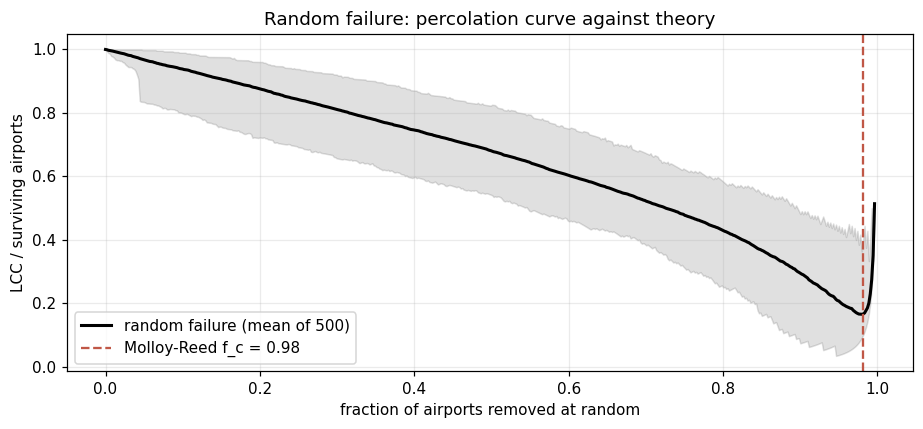

In [12]:
kk = np.array([d for _, d in G.degree()])
kappa = (kk ** 2).mean() / kk.mean()
f_c = 1 - 1 / (kappa - 1)
share = rand_lcc[:, :N - 1] / (N - np.arange(N - 1))                        # LCC as a share of the surviving airports
mean_share = share.mean(0)
f_half = np.argmax(mean_share < 0.5) / N
f_90 = np.argmax(mean_share < 0.9) / N
print(f"<k> = {kk.mean():.2f}, <k^2> = {(kk**2).mean():.1f}, kappa = {kappa:.1f}")
print(f"Molloy-Reed prediction: giant component survives random removal of up to f_c = {f_c:.3f} of the airports")
print(f"Simulation: the LCC holds under 90% of the survivors after f = {f_90:.2f}, and under 50% after f = {f_half:.2f}")

fig, ax = plt.subplots(figsize=(8.5, 4))
f = np.arange(N - 1) / N
ax.plot(f, mean_share, color="black", lw=2, label="random failure (mean of 500)")
ax.fill_between(f, np.percentile(share, 5, axis=0), np.percentile(share, 95, axis=0), color="black", alpha=0.12)
ax.axvline(f_c, color=RED, ls="--", label=f"Molloy-Reed f_c = {f_c:.2f}")
ax.set_xlabel("fraction of airports removed at random"); ax.set_ylabel("LCC / surviving airports"); ax.set_title("Random failure: percolation curve against theory")
ax.legend(); plt.tight_layout(); plt.show()

**Reading this.** In theory the network is **extraordinarily robust to random failure** (f_c = 0.98), because the second moment of the degree distribution is huge (kappa = 55). The simulation agrees that the main network survives almost to the end, but not quite as long as the theory says: by the time 16% of airports are gone, a tenth of the survivors are already cut off (mostly one-link spokes whose hub was removed), and the main network holds less than half of the survivors from about 73% removal. The gap from theory comes from finite size (541 nodes, 28% of them single-link spokes) and from degree correlations (the network is disassortative, M1), which the Molloy-Reed formula ignores. Either way, this is the quantitative form of the paper's statement that the network is "resistant to random attack".

## Part F. Verdict on the paper's claims

In [13]:
sb, sd, sc = res[("static", "betweenness")]["lcc"], res[("static", "degree")]["lcc"], res[("static", "closeness")]["lcc"]
ab = res[("adaptive", "betweenness")]["lcc"]
verdict = pd.DataFrame([
    ("Table 4: top-5 airports by degree, betweenness, closeness", "Reproduced exactly (ORD/DEN order in the degree column is a tie-break: both have 149 connections)", "reproduced"),
    ("Fig. 11: betweenness removal is the most destructive of the 5-node attacks; random barely matters",
     f"Reproduced: after 5 removals the LCC is {sb[5]} (betweenness), {sd[5]} (degree), {sc[5]} (closeness), {rmean[5]:.0f} (random)", "reproduced"),
    ("The network resists random attack but collapses under targeted attack",
     f"Supported and quantified: halving the LCC takes {at.k_to_reach(rmean, N, .5)} random removals ({100 * at.k_to_reach(rmean, N, .5) / N:.0f}% of airports) but only {min(at.k_to_reach(res[('static', m)]['lcc'], N, .5) for m in names)} to {max(at.k_to_reach(res[('static', m)]['lcc'], N, .5) for m in names)} targeted ones (static, seven strategies); Molloy-Reed gives f_c = {f_c:.2f} for random failure", "supported"),
    ("Betweenness removal is the most destructive",
     f"Only for the first few removals. By 50% damage closeness and PageRank ({at.k_to_reach(sc, N, .5)} removals) beat static betweenness ({at.k_to_reach(sb, N, .5)}); adaptive betweenness is the most destructive strategy overall (R = {at.robustness_R(ab, N):.3f}, versus {at.robustness_R(sb, N):.3f} static)", "true in the paper's window only"),
    ("Degree and closeness removal give similar, gentle declines",
     f"Similar for the first 5 ({sd[5]} vs {sc[5]}); afterwards closeness halves the LCC much sooner ({at.k_to_reach(sc, N, .5)} vs {at.k_to_reach(sd, N, .5)} removals) but needs far more removals to finish it (108 vs 52 to reach 10%)", "not beyond the first 5"),
    ("Betweenness nodes are critical bridges between regions",
     "Supported with a mechanism: ANC alone strands 87 Alaskan airports; betweenness targets gateways that strand regions, hubs strategies shrink connectivity broadly", "supported"),
    ("(not in the paper) static rankings are the relevant worst case",
     "No: adaptive attacks lower the robustness index for every centrality, and adaptive betweenness is the single most damaging strategy overall, so the paper's results understate the vulnerability", "new finding"),
], columns=["paper's claim", "what we find", "status"])
verdict.style.hide(axis="index").format(escape="html").set_properties(subset=["paper's claim", "what we find"], **{"text-align": "left", "white-space": "normal"})

paper's claim,what we find,status
"Table 4: top-5 airports by degree, betweenness, closeness",Reproduced exactly (ORD/DEN order in the degree column is a tie-break: both have 149 connections),reproduced
Fig. 11: betweenness removal is the most destructive of the 5-node attacks; random barely matters,"Reproduced: after 5 removals the LCC is 366 (betweenness), 470 (degree), 492 (closeness), 533 (random)",reproduced
The network resists random attack but collapses under targeted attack,"Supported and quantified: halving the LCC takes 192 random removals (35% of airports) but only 15 to 44 targeted ones (static, seven strategies); Molloy-Reed gives f_c = 0.98 for random failure",supported
Betweenness removal is the most destructive,"Only for the first few removals. By 50% damage closeness and PageRank (15 removals) beat static betweenness (19); adaptive betweenness is the most destructive strategy overall (R = 0.036, versus 0.061 static)",true in the paper's window only
"Degree and closeness removal give similar, gentle declines",Similar for the first 5 (470 vs 492); afterwards closeness halves the LCC much sooner (15 vs 35 removals) but needs far more removals to finish it (108 vs 52 to reach 10%),not beyond the first 5
Betweenness nodes are critical bridges between regions,"Supported with a mechanism: ANC alone strands 87 Alaskan airports; betweenness targets gateways that strand regions, hubs strategies shrink connectivity broadly",supported
(not in the paper) static rankings are the relevant worst case,"No: adaptive attacks lower the robustness index for every centrality, and adaptive betweenness is the single most damaging strategy overall, so the paper's results understate the vulnerability",new finding


## Check against the paper

In [14]:
# union-find curves agree with a direct computation
import random
r = random.Random(1)
for _ in range(3):
    o = r.sample(nodes, 40); l, p, c = at.percolation_curves(G, o)
    for k in (0, 5, 20, 40):
        Hk = G.copy(); Hk.remove_nodes_from(o[:k]); cc = [len(x) for x in nx.connected_components(Hk)]
        assert l[k] == max(cc) and c[k] == len(cc) and abs(p[k] - sum(x * (x - 1) for x in cc) / (N * (N - 1))) < 1e-12

for m in paper_t4: assert orders[("static", m)][:5] == paper_t4[m]
assert curves["betweenness"][5] < curves["degree"][5] < curves["closeness"][5] < rmean[5]                 # Fig. 11 ordering
assert curves["betweenness"][1] == 453 and curves["betweenness"][5] == 366
assert 530 <= rmean[5] <= 536 and rlo[5] >= 515 and rhi[5] <= 536 and rlo[5] > curves["closeness"][5] + 25     # random removal barely matters (even its 5th percentile beats every targeted attack)
assert at.k_to_reach(rmean, N, .5) > 4 * max(at.k_to_reach(res[("static", m)]["lcc"], N, .5) for m in names)   # random >> any targeted
winners = {m for m, a, b in runs}
assert len(winners) >= 2                                                                                  # no single strategy wins everywhere
assert at.k_to_reach(res[("static", "closeness")]["lcc"], N, .5) < at.k_to_reach(res[("static", "betweenness")]["lcc"], N, .5)
for m in adaptive_names:                                                                                  # adaptive never less damaging overall
    assert at.robustness_R(res[("adaptive", m)]["lcc"], N) <= at.robustness_R(res[("static", m)]["lcc"], N) + 1e-9, m
assert at.robustness_R(res[("adaptive", "betweenness")]["lcc"], N) == min(at.robustness_R(res[k]["lcc"], N) for k in res)
assert f_c > 0.9
print("All M5 assertions passed.")

All M5 assertions passed.


## Summary and take-aways

- **Reproduced:** Table 4 exactly, and Fig. 11 including its description: after 5 removals the LCC is 366 (betweenness), 470 (degree), 492 (closeness) and about 533 (random, mean of 500 runs).
- **Main message confirmed and quantified:** the network is far more robust to random failure than to targeted attack. Halving the LCC takes about 190 random removals (35% of airports) but only 15 to 44 targeted ones (3% to 8%), about 4 to 13 times fewer. Theory (Molloy-Reed) agrees that random failure is almost harmless.
- **The paper's "betweenness is the most destructive" holds only in its 5-removal window.** The best static strategy changes along the curve, and by 50% damage closeness and PageRank are ahead; "degree and closeness are similar" also holds only at the start.
- **Static rankings understate the vulnerability.** Re-ranking after every removal (adaptive attack) lowers the robustness index for every centrality, and adaptive betweenness is the most damaging attack overall (R = 0.036 vs 0.061 static; 10% LCC after about 43 removals instead of 80). Static lists waste removals on redundant hubs (ORD) and on airports already cut off (BET).
- **The mechanism:** betweenness-based attacks strike *gateways* (ANC then SEA isolate 130 Alaskan airports in two steps); hub-based attacks mostly isolate single-link spokes and lengthen journeys. All targeted attacks fragment the network into 150 to 180 pieces after 20 removals, and efficiency falls faster than the LCC (0.34 vs 0.65 for degree), so the LCC alone understates the damage.
- **Caveats:** all attacks here are purely topological (unweighted, no rerouting, no capacity), which is the paper's setting; the load-based cascade of M9 and the traffic-weighted analysis of M8 add that realism. Results describe the 2014 OpenFlights snapshot.

**Next:** M6 reproduces the threshold-cascade experiment (Section 5.2, Figs. 12 to 14) and ranks *every* airport by how much damage its failure causes.